# Experiment No. 3 — Statistical Analysis and Hypothesis Testing using Python

- **Name:** Abhigyan Dubey
- **Course & Branch:** B.TECH CSE
- **CUID:** CU24250059
- **SUBJECT:** Mastery in Data Analytics and Visualizations and Career Advancement
- **SEM & Section:** 5th SEM, "B"

**Aim:** To perform statistical analysis and hypothesis testing on a real-world dataset to identify relationships between variables, validate assumptions, and support data-driven decisions.

**Dataset:** Titanic Survival Dataset, loaded via `seaborn.load_dataset('titanic')` — no download needed.

---

## Steps 1–3: Select dataset, import libraries, descriptive statistics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

df = sns.load_dataset('titanic').dropna(subset=['age'])
print("Shape:", df.shape)

num = df[['age', 'fare', 'sibsp', 'parch']]
summary = pd.DataFrame({
    'mean': num.mean(),
    'median': num.median(),
    'mode': num.mode().iloc[0],
    'variance': num.var(),
    'std_dev': num.std()
}).round(2)
summary

Shape: (714, 15)


,mean,median,mode,variance,std_dev
age,29.70,28.00,24.0,211.02,14.53
fare,34.69,15.74,13.0,2800.41,52.92
sibsp,0.51,0.00,0.0,0.86,0.93
parch,0.43,0.00,0.0,0.73,0.85


## Step 4: Pearson correlation and correlation matrix

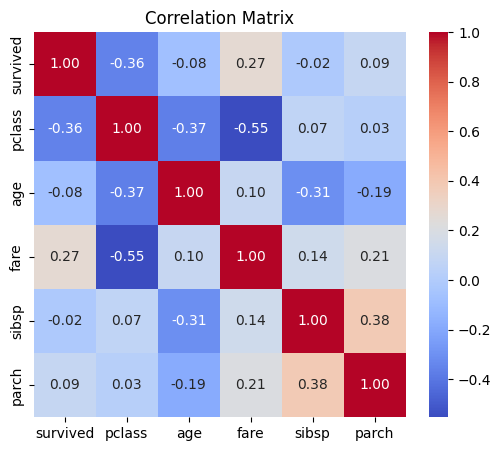

In [2]:
corr = df[['survived', 'pclass', 'age', 'fare', 'sibsp', 'parch']].corr(method='pearson')

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

## Step 5: Formulate hypotheses

**Business problem:** Did passengers who survived pay a different fare than those who did not?

- **H₀:** There is no difference in mean fare between survivors and non-survivors.
- **H₁:** There is a significant difference in mean fare between survivors and non-survivors.

Significance level: **α = 0.05**

## Step 6: Independent Sample t-test

In [3]:
survived = df[df['survived'] == 1]['fare']
not_survived = df[df['survived'] == 0]['fare']

print("Mean fare (survived):    ", round(survived.mean(), 2))
print("Mean fare (not survived):", round(not_survived.mean(), 2))

t_stat, p_val = stats.ttest_ind(survived, not_survived, equal_var=False)  # Welch's t-test
print("\nt-statistic:", round(t_stat, 3))
print("p-value:", p_val)
print("Result:", "Reject H0" if p_val < 0.05 else "Fail to reject H0")

Mean fare (survived):     51.84
Mean fare (not survived): 22.97

t-statistic: 6.548
p-value: 1.9646132697636487e-10
Result: Reject H0


## Step 7: One-Way ANOVA

- **H₀:** Mean age is the same across all three passenger classes.
- **H₁:** Mean age differs in at least one passenger class.

In [4]:
g1 = df[df['pclass'] == 1]['age']
g2 = df[df['pclass'] == 2]['age']
g3 = df[df['pclass'] == 3]['age']

print("Mean age by class:\n", df.groupby('pclass')['age'].mean().round(2))

f_stat, p_anova = stats.f_oneway(g1, g2, g3)
print("\nF-statistic:", round(f_stat, 3))
print("p-value:", p_anova)
print("Result:", "Reject H0" if p_anova < 0.05 else "Fail to reject H0")

Mean age by class:
 pclass
1    38.23
2    29.88
3    25.14
Name: age, dtype: float64

F-statistic: 57.443
p-value: 7.487984171957403e-24
Result: Reject H0


## Step 8: Simple Linear Regression (Age → Fare)

In [5]:
X = sm.add_constant(df['age'])   # independent variable
y = df['fare']                   # dependent variable

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   fare   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     6.632
Date:                Sun, 11 Oct 2026   Prob (F-statistic):             0.0102
Time:                        07:26:37   Log-Likelihood:                -3843.0
No. Observations:                 714   AIC:                             7690.
Df Residuals:                     712   BIC:                             7699.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         24.3009      4.492      5.410      0.0

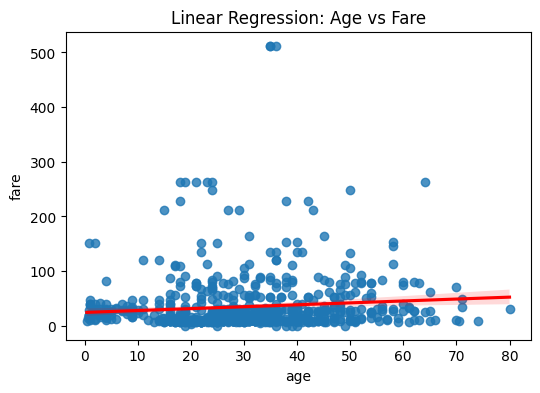

In [6]:
plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='age', y='fare', line_kws={'color': 'red'})
plt.title("Linear Regression: Age vs Fare")
plt.show()

## Step 9: Key regression outputs

In [7]:
print("Intercept:", round(model.params['const'], 3))
print("Slope (age):", round(model.params['age'], 3))
print("p-value (age):", round(model.pvalues['age'], 4))
print("R-squared:", round(model.rsquared, 4))
print("95% CI for slope:", model.conf_int().loc['age'].round(3).tolist())

Intercept: 24.301
Slope (age): 0.35
p-value (age): 0.0102
R-squared: 0.0092
95% CI for slope: [0.083, 0.617]


**Interpretation**

- **Correlation:** `pclass` and `fare` have a strong negative correlation (higher class → higher fare). Other pairs are weak.
- **t-test:** p-value ≈ 2e-10 < 0.05 → reject H₀. Survivors paid a significantly higher mean fare (≈ 51.84 vs ≈ 22.97).
- **ANOVA:** p-value ≈ 7e-24 < 0.05 → reject H₀. Mean age differs across classes (1st ≈ 38, 2nd ≈ 30, 3rd ≈ 25).
- **Regression:** Slope ≈ 0.35 (p = 0.010, 95% CI [0.083, 0.617]) → age has a statistically significant but tiny effect on fare. **R² ≈ 0.009**, so age explains under 1% of fare variation — a poor predictor on its own.

## Step 10: Summary

- Descriptive statistics show fare is highly right-skewed (mean ≫ median, very large variance).
- Fare is strongly tied to passenger class and to survival: survivors paid significantly more (t-test).
- Older passengers were concentrated in higher classes (ANOVA).
- A statistically significant result does not mean a strong one — age is significant for fare but explains <1% of it (low R²).
- Statistical analysis tells businesses *which factors truly matter* and how confident we can be, guiding decisions and choosing features for predictive models.

## Questions

**Q1. What is the difference between descriptive statistics and inferential statistics?**

**Ans:** Descriptive statistics summarize and describe the data you have (mean, median, mode, variance, std. dev., charts). Inferential statistics use a sample to draw conclusions or make predictions about a larger population (hypothesis tests, confidence intervals, regression).

**Q2. Explain the concepts of the Null Hypothesis (H₀) and Alternative Hypothesis (H₁).**

**Ans:** H₀ states there is no effect or no difference (e.g., mean fare of survivors = mean fare of non-survivors). H₁ states there is an effect or difference. We assume H₀ is true and test whether the data provide enough evidence to reject it in favour of H₁.

**Q3. What is a p-value? How is it used to make statistical decisions?**

**Ans:** The p-value is the probability of getting results at least as extreme as the observed ones if H₀ is true. If p < α (usually 0.05), we reject H₀ (result is statistically significant); otherwise we fail to reject H₀.

**Q4. Differentiate between a t-test and ANOVA. In which situations is each test applied?**

**Ans:** A t-test compares the means of **two** groups (e.g., fare of survivors vs non-survivors). ANOVA compares the means of **three or more** groups (e.g., age across 1st, 2nd and 3rd class) using an F-statistic, avoiding the inflated error from running many t-tests.

**Q5. What does the Pearson correlation coefficient indicate? What are its possible values?**

**Ans:** It measures the strength and direction of the **linear** relationship between two numerical variables. Values range from **−1 to +1**: +1 = perfect positive, −1 = perfect negative, 0 = no linear relationship.

**Q6. Explain the significance of R² (Coefficient of Determination) in Linear Regression.**

**Ans:** R² is the proportion of variation in the dependent variable explained by the independent variable(s). It ranges from 0 to 1; higher means a better fit. In our model R² ≈ 0.009, so age explains less than 1% of the variation in fare.

**Q7. Why is statistical analysis important before applying machine learning algorithms?**

**Ans:** It reveals distributions, outliers, skewness and relationships between features and the target, helps select useful features, removes redundant ones, and checks assumptions — leading to better model choice and more reliable results.

**Q8. What assumptions should be satisfied before performing a t-test or ANOVA?**

**Ans:** (1) Data are numerical/continuous, (2) observations are independent, (3) data in each group are approximately normally distributed, (4) variances of groups are roughly equal (homogeneity of variance — otherwise use Welch's t-test), and (5) random sampling.

**Q9. How can regression analysis help organizations in forecasting and decision-making?**

**Ans:** Regression quantifies how one variable changes with another, so organizations can forecast outcomes (sales, demand, house prices), identify key drivers, and test "what-if" scenarios to plan budgets, pricing and resources.

**Q10. Give two real-world applications where hypothesis testing is commonly used in data analytics.**

**Ans:** (1) **A/B testing** — checking whether a new website design significantly increases conversion rate. (2) **HR analytics** — testing whether employees who leave have significantly different monthly income from those who stay.